In [1]:
import json
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../gw_prototype')
from fisheye_camera import CameraCalibrationParameters, cm2pixel
from detection_area import CameraConfiguration, DetectionArea
from geometry import Point

%load_ext autoreload
%autoreload 2

In [2]:
IMG_PTH = "6000015-1221-012345-4040_game_room.jpg"

HEIHGT = 310

In [3]:
img = cv2.imread(IMG_PTH)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (640, 480))

cam4 width = 1021.0, height = 589.0
cam4 with limit width = 931.0, height = 537.0


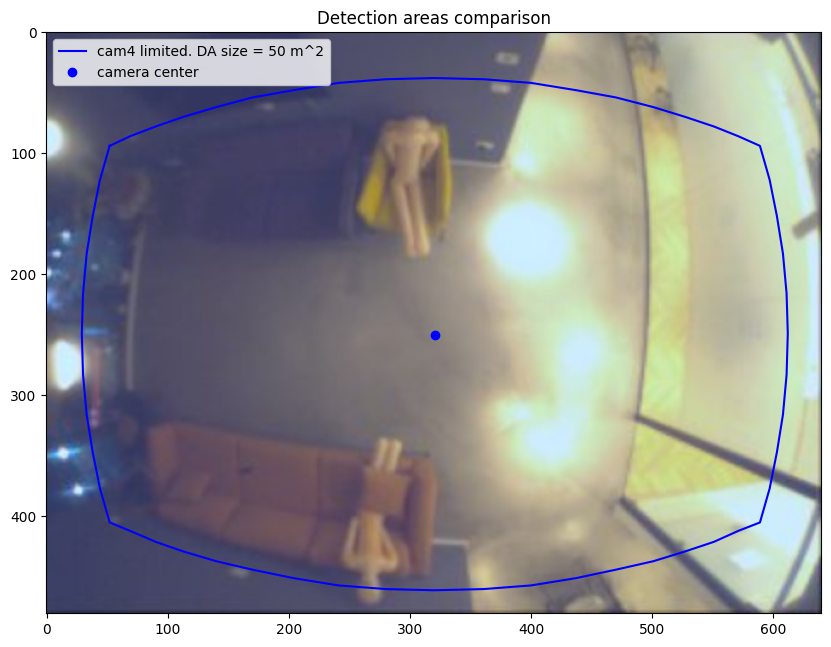

In [4]:
plt.figure(figsize=(10, 10))

# with open("alfa_default.json", "rt") as f:
#     data = json.load(f)
with open("../params/cam4_2_rev_b_main.json", "rt") as f:
    data = json.load(f)
# with open("alfa_sensor_default.json", "rt") as f:
#     data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["LENS_PARAMS"]["CX"],
    data["LENS_PARAMS"]["CY"],
    data["LENS_PARAMS"]["FX"],
    data["LENS_PARAMS"]["FY"],
    data["LENS_PARAMS"]["K0"],
    data["LENS_PARAMS"]["K1"],
    data["LENS_PARAMS"]["K2"],
    data["LENS_PARAMS"]["K3"],
)

cam_config = CameraConfiguration(
    calibration_params,
    data["LENS_PARAMS"]["FOV_X"],
    data["LENS_PARAMS"]["FOV_Y"],
    HEIHGT,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())


center_p = Point(0, 0)
center_p_px = cm2pixel(center_p, HEIHGT, 0, calibration_params)

plt.imshow(img)
# plt.plot(poly[:, 0], poly[:, 1], 'r-', label=f"cam4. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

da_cam3 = DetectionArea(cam_config, True)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'b-', label=f"cam4 limited. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 with limit width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

plt.plot(center_p_px.x, center_p_px.y, 'bo', label="camera center")

plt.ylim(480, 0)

plt.title("Detection areas comparison")
plt.legend(loc='upper left')

(-512.05, 512.05, -295.35, 295.35)

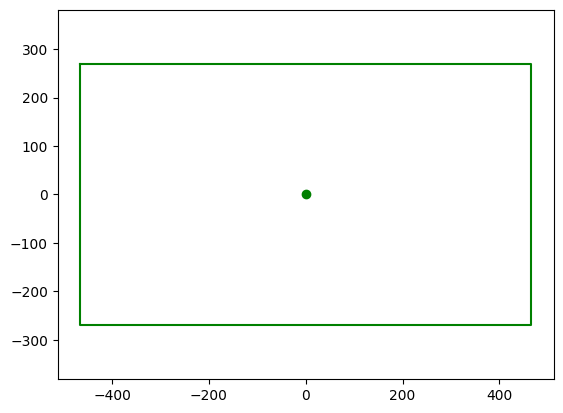

In [5]:
poly = da_cam3.get_cm_polygon()
poly = np.array(poly)
plt.figure()
plt.plot(poly[:, 0], poly[:, 1], 'g-', label="cam4 limited in meters")
plt.plot(0, 0, 'go', label="camera center")
plt.axis("equal")